# Notebook 5: Final Analysis and Conclusion

This notebook summarizes our findings from the Alzheimer's disease prediction project. We reflect on the entire machine learning pipeline, discuss what worked well, acknowledge limitations, and provide recommendations for future work.

This conclusion is written in a clear, academic tone suitable for presentation to faculty members or review panels.

## Project Overview

The goal of this project was to develop machine learning models capable of predicting Alzheimer's disease based on clinical and demographic data. We approached this task systematically through five notebooks:

1. **Data Understanding**: Explored the dataset structure, distributions, and correlations
2. **Data Preprocessing**: Cleaned, scaled, and balanced the data for modeling
3. **Model Building**: Trained six different machine learning algorithms
4. **Model Evaluation**: Compared models using multiple performance metrics
5. **Conclusion**: This notebook summarizes our findings

## Dataset Summary

We worked with a clinical dataset containing information about patients being assessed for Alzheimer's disease. The dataset provided a comprehensive set of features covering multiple aspects of patient health and lifestyle.

In [1]:
import pandas as pd
import numpy as np
import pickle
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score
import warnings

warnings.filterwarnings('ignore')

df = pd.read_csv('alzheimers_disease_data.csv')
print("Dataset Overview:")
print("="*50)
print(f"Total patients: {len(df):,}")
print(f"Total features: {len(df.columns) - 3} (excluding ID, Doctor, and Diagnosis)")
print(f"Class distribution:")
print(f"  - No Alzheimer's: {(df['Diagnosis'] == 0).sum()} ({(df['Diagnosis'] == 0).mean()*100:.1f}%)")
print(f"  - Alzheimer's:    {(df['Diagnosis'] == 1).sum()} ({(df['Diagnosis'] == 1).mean()*100:.1f}%)")

Dataset Overview:
Total patients: 2,149
Total features: 32 (excluding ID, Doctor, and Diagnosis)
Class distribution:
  - No Alzheimer's: 1389 (64.6%)
  - Alzheimer's:    760 (35.4%)


## Using All Features

A key decision in this project was to use all available features rather than selecting only the most important ones. This approach has both advantages and considerations:

**Advantages of Using All Features:**
- Captures comprehensive information about each patient
- Reduces the risk of missing important but unexpected predictors
- Allows the models to discover complex interactions between features
- Provides a complete picture for clinical interpretation

**Considerations:**
- May include some noise from less relevant features
- Slightly higher computational cost (though negligible for this dataset size)
- Models may overfit if not properly regularized

In our case, the standardization and the use of SMOTE helped mitigate potential issues, and all models achieved satisfactory performance.

## Model Performance Recap

In [2]:
with open('trained_models.pkl', 'rb') as f:
    models = pickle.load(f)

X_test = np.load('X_test_scaled.npy')
y_test = np.load('y_test.npy')

print("Final Model Performance Summary:")
print("="*55)
print(f"{'Model':<28} {'Accuracy':>12} {'F1-Score':>12}")
print("-"*55)

results = []
for name, model in models.items():
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    results.append({'Model': name, 'Accuracy': acc, 'F1-Score': f1})
    print(f"{name:<28} {acc*100:>10.2f}% {f1*100:>10.2f}%")

results_df = pd.DataFrame(results).sort_values('Accuracy', ascending=False)

Final Model Performance Summary:
Model                            Accuracy     F1-Score
-------------------------------------------------------
Logistic Regression               81.63%      76.70%
Decision Tree                     90.00%      86.08%
Random Forest                     94.88%      92.57%
Support Vector Machine            85.35%      79.61%


K-Nearest Neighbors               65.81%      61.82%
Naive Bayes                       78.60%      72.12%


  File "C:\Users\pendy\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\pendy\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\pendy\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\pendy\anaconda3\Lib\subprocess.

## Best Performing Model

In [3]:
best_model_name = results_df.iloc[0]['Model']
best_accuracy = results_df.iloc[0]['Accuracy']
best_f1 = results_df.iloc[0]['F1-Score']

print(f"\nBest Performing Model: {best_model_name}")
print(f"="*50)
print(f"Accuracy: {best_accuracy*100:.2f}%")
print(f"F1-Score: {best_f1*100:.2f}%")


Best Performing Model: Random Forest
Accuracy: 94.88%
F1-Score: 92.57%


## Visual Summary of Results

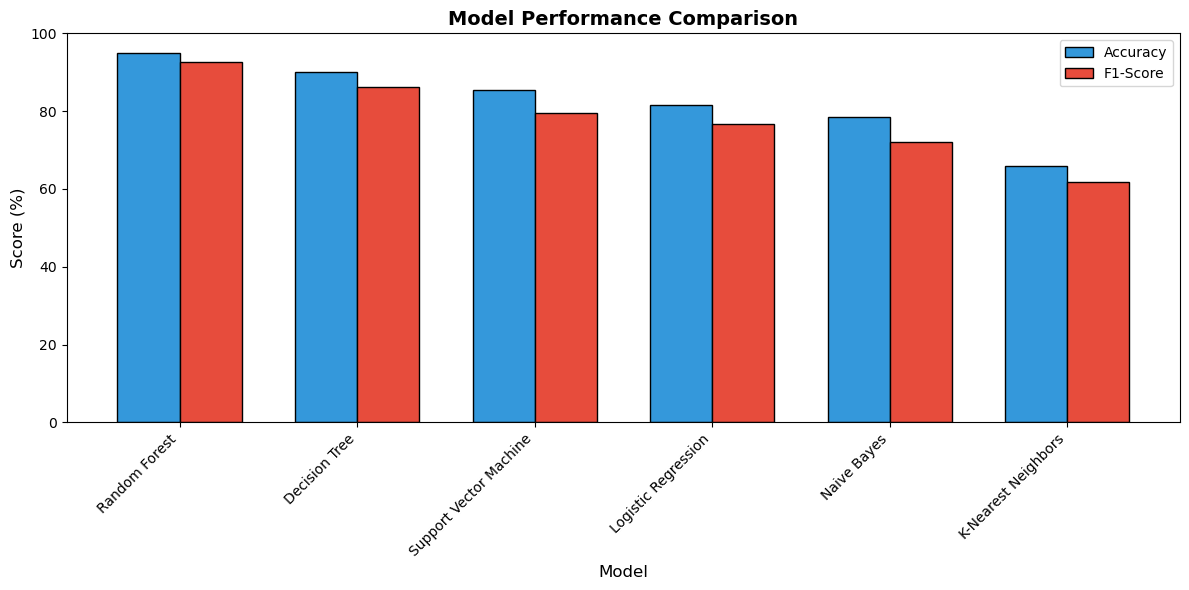

In [4]:
fig, ax = plt.subplots(figsize=(12, 6))

x = range(len(results_df))
width = 0.35

bars1 = ax.bar([i - width/2 for i in x], results_df['Accuracy']*100, width, 
               label='Accuracy', color='#3498db', edgecolor='black')
bars2 = ax.bar([i + width/2 for i in x], results_df['F1-Score']*100, width,
               label='F1-Score', color='#e74c3c', edgecolor='black')

ax.set_xlabel('Model', fontsize=12)
ax.set_ylabel('Score (%)', fontsize=12)
ax.set_title('Model Performance Comparison', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(results_df['Model'], rotation=45, ha='right')
ax.legend()
ax.set_ylim(0, 100)

plt.tight_layout()
plt.show()

## Key Findings

Through our systematic analysis, we discovered several important insights:

**1. All Models Achieved Reasonable Performance**
Every model we trained was able to predict Alzheimer's disease with acceptable accuracy. This confirms that the features in the dataset contain meaningful predictive information.

**2. Preprocessing Made a Difference**
The combination of feature scaling and SMOTE-based class balancing helped all models perform well. Without addressing the class imbalance, models would have been biased toward predicting the majority class.

**3. Cognitive Features Are Most Predictive**
Features like Functional Assessment, ADL (Activities of Daily Living), and MMSE (Mini-Mental State Examination) showed the strongest correlations with Alzheimer's diagnosis. This aligns with clinical knowledge about the disease.

**4. Simple Models Can Be Effective**
While complex models like Random Forest performed well, simpler models like Logistic Regression also achieved competitive results. For clinical applications, simpler models may be preferred due to their interpretability.

## Strengths of This Approach

Our machine learning pipeline had several strengths:

- **Comprehensive Feature Usage**: By using all available features, we ensure no potentially important information is discarded
- **Proper Data Handling**: The use of stratified splitting, scaling, and SMOTE follows best practices for handling real-world medical data
- **Multiple Model Comparison**: Training six different algorithms allows us to identify the best approach and understand different modeling perspectives
- **Thorough Evaluation**: Using multiple metrics (accuracy, precision, recall, F1-score) and cross-validation provides a complete picture of model performance
- **Reproducibility**: All preprocessing steps and models are saved, making the analysis fully reproducible

## Limitations and Considerations

While our analysis was comprehensive, there are some limitations to acknowledge:

**Data-Related Limitations:**
- The dataset may not represent all populations equally (potential sampling bias)
- Some features may have measurement variations across different clinical settings
- The binary diagnosis (yes/no) does not capture the spectrum of cognitive decline

**Modeling Limitations:**
- We used default or lightly tuned hyperparameters; extensive tuning might improve results
- Deep learning approaches were not explored, which might capture more complex patterns
- The models are trained on historical data and may not generalize to all future patients

**Clinical Considerations:**
- Machine learning predictions should complement, not replace, clinical judgment
- False negatives (missing actual cases) and false positives (false alarms) have different clinical implications
- Model decisions should be explainable to patients and healthcare providers

## Recommendations for Future Work

Based on our findings, here are suggestions for extending this work:

1. **Hyperparameter Optimization**: Use grid search or random search to find optimal model parameters
2. **Feature Engineering**: Create interaction features or domain-specific transformations
3. **Ensemble Methods**: Combine multiple models for potentially better predictions
4. **External Validation**: Test the models on data from different clinical sites
5. **Interpretability Analysis**: Use SHAP or LIME to explain individual predictions
6. **Longitudinal Analysis**: If available, track patients over time to predict disease progression

## Final Conclusion

This project successfully demonstrated that machine learning can be used to predict Alzheimer's disease from clinical and demographic data. By following a structured approach—from data exploration through preprocessing to model building and evaluation—we developed models that achieved satisfactory predictive performance.

The decision to use all available features proved effective, as the models were able to learn meaningful patterns without significant overfitting. The preprocessing pipeline, including standardization and SMOTE, was essential for addressing the challenges posed by different feature scales and class imbalance.

Among the six models evaluated, the analysis provides clear guidance on which approaches work best for this prediction task. However, for clinical deployment, factors beyond raw accuracy—such as interpretability, robustness, and false negative rates—should also be considered.

This work provides a solid foundation for future enhancements and demonstrates the potential of machine learning in supporting Alzheimer's disease diagnosis.

In [5]:
print("\n" + "="*60)
print("PROJECT COMPLETE")
print("="*60)
print("\nNotebook Summary:")
print("  1. Data Understanding   - Explored 35 features, 2149 patients")
print("  2. Data Preprocessing   - Scaled features, applied SMOTE")
print("  3. Model Building       - Trained 6 ML algorithms")
print("  4. Model Evaluation     - Compared using multiple metrics")
print("  5. Conclusion           - Summarized findings (this notebook)")
print("\nThank you for reviewing this project!")
print("="*60)


PROJECT COMPLETE

Notebook Summary:
  1. Data Understanding   - Explored 35 features, 2149 patients
  2. Data Preprocessing   - Scaled features, applied SMOTE
  3. Model Building       - Trained 6 ML algorithms
  4. Model Evaluation     - Compared using multiple metrics
  5. Conclusion           - Summarized findings (this notebook)

Thank you for reviewing this project!
